# CSSD 模型（横截面收益标准差模型）

**用于检验羊群效应的行为金融模型**

$$
\text{CSSD} = \sqrt{\frac{\sum_{i=1}^{N} (r_i - r_m)^2}{N - 1}}
$$

其中：

$$
r_i \text{ 为个股 } i \text{ 的收益率}
$$$$
r_m \text{ 为市场组合的收益率}
$$$$
N \text{ 为样本中的股票数量}
$$

以 CSSD 作为被解释变量，以两个虚拟变量 $ D_t^u $ 和 $ D_t^d $ 作为解释变量，进行如下时序回归：

$$
\text{CSSD}_t = \alpha + \beta_1 D_t^u + \beta_2 D_t^d + \varepsilon_t
$$

其中：

$$
D_t^u = \begin{cases}1, & \text{若市场收益 } r_{m,t} \text{ 高于给定的上涨阈值} \\0, & \text{否则}\end{cases}
$$$$
D_t^d = \begin{cases}1, & \text{若市场收益 } r_{m,t} \text{ 低于给定的下跌阈值} \\0, & \text{否则}\end{cases}
$$

## 模型说明

CSSD 模型对羊群效应的检验，主要依据时序回归中市场极端收益项（即 $ D_t^u $ 和 $ D_t^d $）的回归系数 $ \beta_1 $ 和 $ \beta_2 $ 的符号及显著性。当 $ \beta_1 $ 或 $ \beta_2 $ 显著小于 0 时，表明在市场大幅上涨或大幅下跌的极端行情下，横截面收益标准差（CSSD）显著下降，意味着个股收益趋于一致，投资者的买卖行为趋向同步，从而反映出市场中存在明显的羊群效应。

数据：日度收盘价、日度可交易股票数量

In [1]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def calculate_cssd_beta_factor(
    start_date,
    end_date,
    factor_type=0,
    regression_window=252,
    upper_threshold=0.03,
    lower_threshold=-0.03,
    market_ids=None,
    batch_size=500,
    min_market_stocks=500,
    min_extreme_days=5,
):
    """
    计算日频滚动 CSSD 羊群效应因子。

    参数
    ----
    factor_type : int
        0：输出 beta1，即极端上涨日虚拟变量 D_up 的滚动回归系数；
        1：输出 beta2，即极端下跌日虚拟变量 D_down 的滚动回归系数。

    regression_window : int
        每日回归使用的历史交易日窗口，例如 252。

    upper_threshold, lower_threshold : float
        市场极端上涨／下跌阈值。例如 0.03 表示单日上涨超过 3%。

    返回
    ----
    DataFrame
        单层日期索引，列名为 CSSD_beta1 或 CSSD_beta2。
        每个 T 日的值仅使用截至 T 日的数据估计，可用于 T+1 日交易。
    """
    if factor_type not in (0, 1):
        raise ValueError("factor_type 只能为 0（beta1）或 1（beta2）。")

    if lower_threshold >= upper_threshold:
        raise ValueError("lower_threshold 必须小于 upper_threshold。")

    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        # 252 个 CSSD 观测值需要额外取 252 个交易日价格
        lookback_days=regression_window,
    )

    market_ids = _get_ids(market_ids)
    return_dates = price_dates[1:]

    # 汇总每日的收益和、收益平方和、有效股票数。
    return_sum = pd.Series(0.0, index=return_dates)
    return_sq_sum = pd.Series(0.0, index=return_dates)
    stock_count = pd.Series(0, index=return_dates, dtype="int64")

    for start in range(0, len(market_ids), batch_size):
        batch = market_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(batch, price_dates)
        if close is None:
            continue

        returns = _get_returns(close, volume)

        return_sum += returns.sum(axis=1, skipna=True)
        return_sq_sum += returns.pow(2).sum(axis=1, skipna=True)
        stock_count += returns.notna().sum(axis=1).astype("int64")

    # r_m,t：全市场当日有效股票收益率等权平均。
    market_return = return_sum / stock_count.replace(0, np.nan)

    # CSSD_t^2 = [sum(r_i^2) - N * r_m^2] / (N - 1)
    squared_deviation_sum = (
        return_sq_sum - stock_count * market_return.pow(2)
    ).clip(lower=0)

    cssd = np.sqrt(
        squared_deviation_sum / (stock_count - 1).replace(0, np.nan)
    )

    state = pd.DataFrame({
        "market_return": market_return,
        "CSSD": cssd,
        "N": stock_count,
    })

    # 有效股票太少的交易日不参与回归。
    state.loc[
        state["N"] < min_market_stocks,
        ["market_return", "CSSD"],
    ] = np.nan

    state = state.dropna(subset=["market_return", "CSSD"]).copy()

    # D_up 对应 beta1；D_down 对应 beta2。
    state["D_up"] = (
        state["market_return"] > upper_threshold
    ).astype(float)

    state["D_down"] = (
        state["market_return"] < lower_threshold
    ).astype(float)

    beta_result = pd.DataFrame(
        np.nan,
        index=state.index,
        columns=["CSSD_beta1", "CSSD_beta2"],
    )

    # 每个交易日 T 都仅使用截至 T 的 regression_window 个交易日回归。
    for end_pos in range(regression_window - 1, len(state)):
        sample = state.iloc[
            end_pos - regression_window + 1:end_pos + 1
        ]

        # 若窗口中上涨或下跌极端日过少，系数不具可解释性。
        if (
            sample["D_up"].sum() < min_extreme_days
            or sample["D_down"].sum() < min_extreme_days
        ):
            continue

        y = sample["CSSD"].values
        X = np.column_stack([
            np.ones(len(sample)),
            sample["D_up"].values,
            sample["D_down"].values,
        ])

        # alpha、beta1、beta2
        coefficients = np.linalg.lstsq(X, y, rcond=None)[0]

        beta_result.iloc[end_pos, 0] = coefficients[1]
        beta_result.iloc[end_pos, 1] = coefficients[2]

    # 最终只输出用户要求区间内的日频因子。
    beta_result = beta_result.reindex(target_dates)

    if factor_type == 0:
        return beta_result[["CSSD_beta1"]]
    else:
        return beta_result[["CSSD_beta2"]]

In [2]:
cssd_beta1 = calculate_cssd_beta_factor(
    start_date="2020-01-01",
    end_date="2025-12-31",
    factor_type=0,
    regression_window=252,
    upper_threshold=0.02,
    lower_threshold=-0.02,
)

cssd_beta1.head()

,CSSD_beta1
2020-01-02,-0.000289
2020-01-03,-0.000312
2020-01-06,-0.000339
2020-01-07,-0.000352
2020-01-08,-0.000364


,指标,数值,判断
0,总交易日数,1455,
1,有效 beta 观测数,1360,
2,缺失值数,95,初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3,最长连续缺失天数,59,若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4,重复日期,0,应为 0
5,日期是否升序,True,应为 True
6,无穷值,0,应为 0
7,首个有效 beta 日期,2020-01-02,通常在滚动窗口形成后才出现
8,负 beta 占比,0.114706,负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9,均值,0.002885,单位为收益率；0.01 表示 1 个百分点


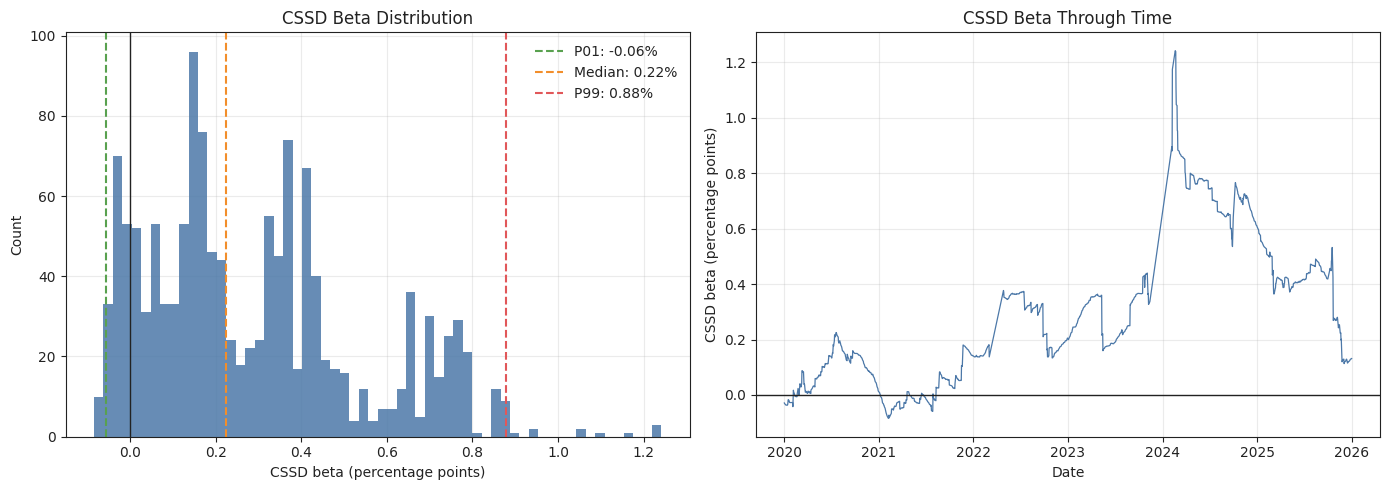

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 若检验 beta2，只需改为 cssd_beta2 和 "CSSD_beta2"
factor = cssd_beta1.copy()
factor_name = "CSSD_beta1"
review_threshold = 0.05  # |beta| 超过 5 个百分点时人工核查

# 兼容 Series 或单列 DataFrame
if isinstance(factor, pd.Series):
    factor = factor.to_frame(name=factor_name)

if factor_name not in factor.columns:
    factor_name = factor.columns[0]

beta = pd.to_numeric(factor[factor_name], errors="coerce")
beta.index = pd.to_datetime(beta.index)

duplicate_count = int(beta.index.duplicated().sum())
is_sorted = beta.index.is_monotonic_increasing
missing_count = int(beta.isna().sum())
inf_count = int(np.isinf(beta.dropna().values).sum())

valid = beta.replace([np.inf, -np.inf], np.nan).dropna()
if valid.empty:
    raise ValueError("没有有效的 CSSD beta 值，请检查回归窗口和极端日阈值。")

invalid = beta.replace([np.inf, -np.inf], np.nan).isna()
longest_missing_run = int(
    invalid.groupby((~invalid).cumsum()).sum().max()
)

summary = pd.DataFrame({
    "指标": [
        "总交易日数",
        "有效 beta 观测数",
        "缺失值数",
        "最长连续缺失天数",
        "重复日期",
        "日期是否升序",
        "无穷值",
        "首个有效 beta 日期",
        "负 beta 占比",
        "均值",
        "标准差",
        "最小值",
        "1%分位数",
        "中位数",
        "99%分位数",
        "最大值",
        "|beta| > 5% 的观测数",
        "日变化绝对值 99%分位数",
    ],
    "数值": [
        len(beta),
        len(valid),
        missing_count,
        longest_missing_run,
        duplicate_count,
        is_sorted,
        inf_count,
        valid.index.min().strftime("%Y-%m-%d"),
        (valid < 0).mean(),
        valid.mean(),
        valid.std(),
        valid.min(),
        valid.quantile(0.01),
        valid.median(),
        valid.quantile(0.99),
        valid.max(),
        int((valid.abs() > review_threshold).sum()),
        valid.diff().abs().quantile(0.99),
    ],
    "判断": [
        "",
        "",
        "初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误",
        "若中间出现很长缺失，检查 min_extreme_days 与市场阈值",
        "应为 0",
        "应为 True",
        "应为 0",
        "通常在滚动窗口形成后才出现",
        "负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号",
        "单位为收益率；0.01 表示 1 个百分点",
        "检查 beta 的时间稳定性",
        "无需强制为正或负",
        "",
        "",
        "",
        "",
        "超过阈值仅人工复核，不自动判错",
        "过大跳变需检查滚动窗口中的极端日变化",
    ],
})

display(summary)

# ---------- 绘图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
})

beta_pct = valid * 100
p01, p50, p99 = valid.quantile([0.01, 0.50, 0.99]).values * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左：分布
axes[0].hist(beta_pct, bins=60, color="#4C78A8", alpha=0.85)
axes[0].axvline(0, color="#222222", linewidth=1)
axes[0].axvline(p01, color="#59A14F", linestyle="--", label="P01: {:.2f}%".format(p01))
axes[0].axvline(p50, color="#F28E2B", linestyle="--", label="Median: {:.2f}%".format(p50))
axes[0].axvline(p99, color="#E15759", linestyle="--", label="P99: {:.2f}%".format(p99))
axes[0].set_title("CSSD Beta Distribution")
axes[0].set_xlabel("CSSD beta (percentage points)")
axes[0].set_ylabel("Count")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 右：时间序列
axes[1].plot(valid.index, beta_pct, color="#4C78A8", linewidth=0.9)
axes[1].axhline(0, color="#222222", linewidth=1)
axes[1].set_title("CSSD Beta Through Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("CSSD beta (percentage points)")
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

'''
upper_threshold=0.03
lower_threshold=-0.03

指标	数值	判断
0	总交易日数	1455	
1	有效 beta 观测数	687	
2	缺失值数	768	初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3	最长连续缺失天数	708	若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4	重复日期	0	应为 0
5	日期是否升序	True	应为 True
6	无穷值	0	应为 0
7	首个有效 beta 日期	2020-01-02	通常在滚动窗口形成后才出现
8	负 beta 占比	0.250364	负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9	均值	0.00453444	单位为收益率；0.01 表示 1 个百分点
10	标准差	0.00436959	检查 beta 的时间稳定性
11	最小值	-0.00162186	无需强制为正或负
12	1%分位数	-0.00149711	
13	中位数	0.00566154	
14	99%分位数	0.0112108	
15	最大值	0.011226	
16	|beta| > 5% 的观测数	0	超过阈值仅人工复核，不自动判错
17	日变化绝对值 99%分位数	0.00143277	过大跳变需检查滚动窗口中的极端日变化
'''

plt.tight_layout()
plt.show()

In [4]:
cssd_beta2 = calculate_cssd_beta_factor(
    start_date="2020-01-01",
    end_date="2025-12-31",
    factor_type=1,
    regression_window=252,
    upper_threshold=0.02,
    lower_threshold=-0.02,
)

cssd_beta2.head()

,CSSD_beta2
2020-01-02,0.005403
2020-01-03,0.005380
2020-01-06,0.005353
2020-01-07,0.005340
2020-01-08,0.005328


,指标,数值,判断
0,总交易日数,1455,
1,有效 beta 观测数,1360,
2,缺失值数,95,初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3,最长连续缺失天数,59,若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4,重复日期,0,应为 0
5,日期是否升序,True,应为 True
6,无穷值,0,应为 0
7,首个有效 beta 日期,2020-01-02,通常在滚动窗口形成后才出现
8,负 beta 占比,0.0,负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9,均值,0.005219,单位为收益率；0.01 表示 1 个百分点


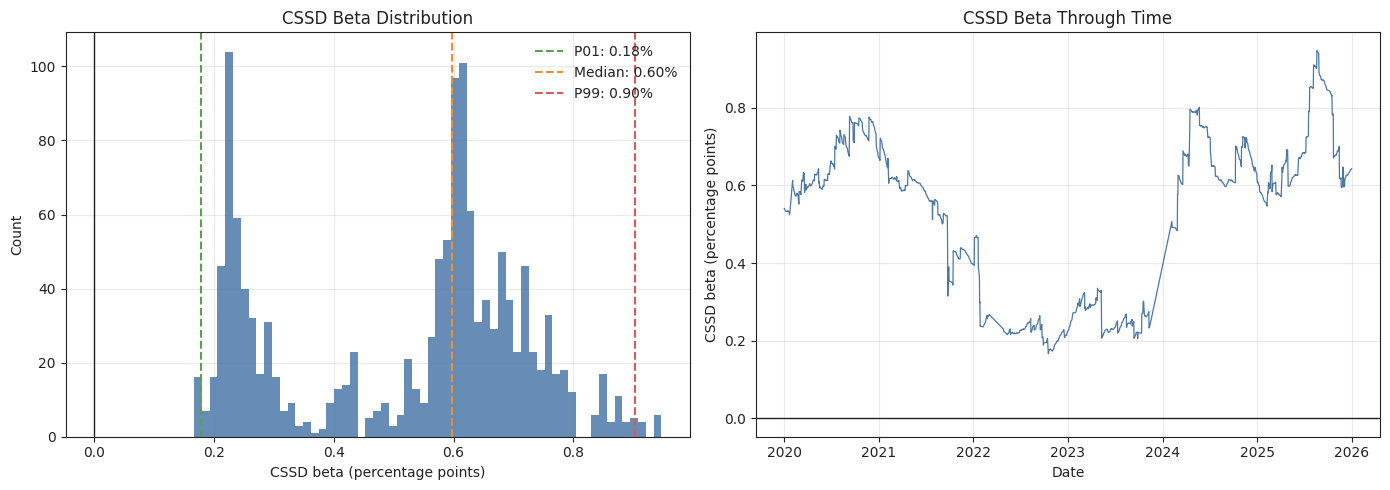

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 若检验 beta2，只需改为 cssd_beta2 和 "CSSD_beta2"
factor = cssd_beta2.copy()
factor_name = "CSSD_beta2"
review_threshold = 0.05  # |beta| 超过 5 个百分点时人工核查

# 兼容 Series 或单列 DataFrame
if isinstance(factor, pd.Series):
    factor = factor.to_frame(name=factor_name)

if factor_name not in factor.columns:
    factor_name = factor.columns[0]

beta = pd.to_numeric(factor[factor_name], errors="coerce")
beta.index = pd.to_datetime(beta.index)

duplicate_count = int(beta.index.duplicated().sum())
is_sorted = beta.index.is_monotonic_increasing
missing_count = int(beta.isna().sum())
inf_count = int(np.isinf(beta.dropna().values).sum())

valid = beta.replace([np.inf, -np.inf], np.nan).dropna()
if valid.empty:
    raise ValueError("没有有效的 CSSD beta 值，请检查回归窗口和极端日阈值。")

invalid = beta.replace([np.inf, -np.inf], np.nan).isna()
longest_missing_run = int(
    invalid.groupby((~invalid).cumsum()).sum().max()
)

summary = pd.DataFrame({
    "指标": [
        "总交易日数",
        "有效 beta 观测数",
        "缺失值数",
        "最长连续缺失天数",
        "重复日期",
        "日期是否升序",
        "无穷值",
        "首个有效 beta 日期",
        "负 beta 占比",
        "均值",
        "标准差",
        "最小值",
        "1%分位数",
        "中位数",
        "99%分位数",
        "最大值",
        "|beta| > 5% 的观测数",
        "日变化绝对值 99%分位数",
    ],
    "数值": [
        len(beta),
        len(valid),
        missing_count,
        longest_missing_run,
        duplicate_count,
        is_sorted,
        inf_count,
        valid.index.min().strftime("%Y-%m-%d"),
        (valid < 0).mean(),
        valid.mean(),
        valid.std(),
        valid.min(),
        valid.quantile(0.01),
        valid.median(),
        valid.quantile(0.99),
        valid.max(),
        int((valid.abs() > review_threshold).sum()),
        valid.diff().abs().quantile(0.99),
    ],
    "判断": [
        "",
        "",
        "初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误",
        "若中间出现很长缺失，检查 min_extreme_days 与市场阈值",
        "应为 0",
        "应为 True",
        "应为 0",
        "通常在滚动窗口形成后才出现",
        "负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号",
        "单位为收益率；0.01 表示 1 个百分点",
        "检查 beta 的时间稳定性",
        "无需强制为正或负",
        "",
        "",
        "",
        "",
        "超过阈值仅人工复核，不自动判错",
        "过大跳变需检查滚动窗口中的极端日变化",
    ],
})

display(summary)

# ---------- 绘图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
})

beta_pct = valid * 100
p01, p50, p99 = valid.quantile([0.01, 0.50, 0.99]).values * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左：分布
axes[0].hist(beta_pct, bins=60, color="#4C78A8", alpha=0.85)
axes[0].axvline(0, color="#222222", linewidth=1)
axes[0].axvline(p01, color="#59A14F", linestyle="--", label="P01: {:.2f}%".format(p01))
axes[0].axvline(p50, color="#F28E2B", linestyle="--", label="Median: {:.2f}%".format(p50))
axes[0].axvline(p99, color="#E15759", linestyle="--", label="P99: {:.2f}%".format(p99))
axes[0].set_title("CSSD Beta Distribution")
axes[0].set_xlabel("CSSD beta (percentage points)")
axes[0].set_ylabel("Count")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 右：时间序列
axes[1].plot(valid.index, beta_pct, color="#4C78A8", linewidth=0.9)
axes[1].axhline(0, color="#222222", linewidth=1)
axes[1].set_title("CSSD Beta Through Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("CSSD beta (percentage points)")
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

'''
upper_threshold=0.03
lower_threshold=-0.03

指标	数值	判断
0	总交易日数	1455	
1	有效 beta 观测数	687	
2	缺失值数	768	初始缺失可能来自 252 日回归窗口或极端日不足，不一定是错误
3	最长连续缺失天数	708	若中间出现很长缺失，检查 min_extreme_days 与市场阈值
4	重复日期	0	应为 0
5	日期是否升序	True	应为 True
6	无穷值	0	应为 0
7	首个有效 beta 日期	2020-01-02	通常在滚动窗口形成后才出现
8	负 beta 占比	0	负值表示极端上涨日 CSSD 低于普通日；是羊群效应的候选信号
9	均值	0.00988442	单位为收益率；0.01 表示 1 个百分点
10	标准差	0.00102633	检查 beta 的时间稳定性
11	最小值	0.0080556	无需强制为正或负
12	1%分位数	0.00812307	
13	中位数	0.00982598	
14	99%分位数	0.0123125	
15	最大值	0.0123272	
16	|beta| > 5% 的观测数	0	超过阈值仅人工复核，不自动判错
17	日变化绝对值 99%分位数	0.00114114	过大跳变需检查滚动窗口中的极端日变化
'''

'''
旧结果分析

数据本身没有完整性或数值异常，但当前参数下滚动回归的可用性不足。
项目	beta1（上涨极端）	beta2（下跌极端）	结论
有效观测	687 / 1455	687 / 1455	仅 47.2% 可用
最长连续缺失	708 日	708 日	明显过长
均值	+0.453 个百分点	+0.988 个百分点	CSSD 在极端日平均上升
负值占比	25.0%	0%	下跌情形没有羊群效应方向


关键结论：
- 结构质量通过：无重复、无无穷值、日期有序，beta 的数值范围也合理，没有异常爆点。
- beta1 只有 25% 为负，且最小仅为 -0.162 个百分点；均值与中位数都为正。
- beta2 全部为正，意味着极端下跌日的 CSSD 比普通日更高，个股分歧扩大，而非收益趋同。
- 因此，就当前样本和参数而言，没有看到稳定的 CSSD 羊群效应证据。正式结论仍需回归 t 值或置信区间支持。
- 708 日连续缺失不是数据坏了，而是滚动 252 日窗口中，市场收益 > 3% 或 < -3% 的天数不足 5 天。你的代码要求上下两类极端日都至少出现 5 次，因此 beta1、beta2 会在同一时期同时缺失。
首个有效值是 2020-01-02 是正常的：计算函数已额外取了 2019 年的 252 日历史价格。
如果希望得到连续、可用的日频滚动 beta，建议先将阈值改为：
upper_threshold=0.02
lower_threshold=-0.02
min_extreme_days=5
再重新运行同样的检查。2% 阈值会增加极端日样本，通常能显著减少长时间缺失；然后比较新旧阈值下 beta 的符号和稳定性。
'''

'''
新结果分析：

这组参数明显更合适：有效覆盖率从 47.2% 提升到 93.5%，最长连续缺失从 708 日降到 59 日。数据完整性、分布和稳定性都可以通过。
- beta1：均值 +0.288 个百分点，仅 11.5% 为负；
- beta2：均值 +0.522 个百分点，全样本始终为正；
- 两者均没有异常极值，日变化也比原参数更平稳。
经济解释上，结论仍然很清楚：在当前全 A 等权市场收益、2% 阈值和 252 日窗口下，极端上涨或下跌日的 CSSD 通常上升，而不是下降。尤其 beta2 始终为正，表示市场下跌较大时股票收益分歧扩大，并未出现 CSSD 模型定义的下跌羊群效应。
因此：
- 因子输出质量：通过；
- 参数可用性：2% 阈值优于 3% 阈值；
- 羊群效应结论：当前仅从系数方向看，不支持显著羊群效应。
正式研究报告中还需要补充滚动回归系数的 t 值或置信区间；只有 beta 显著小于 0，才能严格确认羊群效应。
'''

plt.tight_layout()
plt.show()

你的结果讲的是一个很清晰的金融故事：在 2020–2025 的全 A 等权市场中，市场出现较大波动时，股票之间的收益分歧通常扩大，而不是收敛。因此，按 CSSD 的定义，数据并不支持明显的羊群效应。

## 先把 CSSD 翻译成直觉

CSSD 不是一只股票的波动率，而是“**同一天，不同股票的收益离市场平均收益有多远**”。

- 如果市场上涨 2%，大多数股票也都在约 2% 附近上涨，例如 1.8%、2.0%、2.2%，则 CSSD 很低：大家走势一致。
- 如果市场上涨 2%，但有的股票涨 8%，有的涨 2%，有的跌 3%，则 CSSD 很高：大家对行情的反应不同。

羊群效应的核心假设是：市场剧烈波动时，投资者放弃一部分自身信息、跟随市场共识买卖，因此股票收益会向市场收益靠拢，CSSD 应下降。Christie 和 Huang 的原始 CSSD 思路正是用“极端市场日的横截面离散度是否降低”来识别这种现象；相反，传统理性定价下，不同股票对市场冲击的敏感度不同，离散度往往会上升。[原始 CSSD 研究](https://www.tandfonline.com/doi/abs/10.2469/faj.v51.n4.1918)

## 你的回归系数究竟表示什么

由于 `D_up`、`D_down` 和普通日互斥，你的回归可以直接理解为：

| 市场状态 | 预期 CSSD |
|---|---|
| 普通日 | `α` |
| 市场收益 > 2% | `α + β1` |
| 市场收益 < -2% | `α + β2` |

所以：

- `β1 < 0`：极端上涨日的 CSSD 比普通日低，支持上涨羊群；
- `β2 < 0`：极端下跌日的 CSSD 比普通日低，支持下跌羊群；
- `β > 0`：极端行情下 CSSD 更高，股票反应更分化，不支持 CSSD 羊群。

你的 beta 单位和收益率相同。`0.002885` 不是 0.2885%，而是 **CSSD 增加 0.2885 个百分点，即 28.85 个基点**。

## 结合你的 2% 阈值结果

### 上涨极端日：beta1

`beta1` 均值为 `+0.002885`，中位数为 `+0.002242`。

这意味着，在过去 252 个交易日的滚动样本中，市场单日上涨超过 2% 时，CSSD 平均比普通日高约 **0.29 个百分点**。也就是说，行情大涨时并非所有股票同步上行，反而出现了更明显的强弱分化。

虽然 11.5% 的滚动窗口中 beta1 为负，但负值很小：

- 最低值仅 `-0.000843`，即 -8.43 个基点；
- 99% 分位数为 `+0.008793`，即 +87.93 个基点；
- 均值和中位数都为正。

所以，beta1 的总体信息不是“上涨时存在稳定羊群”，而是“上涨时通常分化，少数时期可能出现轻微收敛”。

### 下跌极端日：beta2

`beta2` 全部为正，范围为：

- 最小值：`+0.001670`，即 +16.70 个基点；
- 中位数：`+0.005977`，即 +59.77 个基点；
- 均值：`+0.005219`，即 +52.19 个基点。

这比 beta1 更明确：市场下跌超过 2% 时，CSSD 从未低于普通日，而是稳定上升。直觉上，虽然市场整体下跌，但不同股票并没有“一起跌、按相近幅度跌”；有的跌得更重，有的相对抗跌，横截面分歧被放大。

因此，就 CSSD 的判别标准而言，**下跌时不存在羊群效应证据**；结果反而更接近“压力行情下的收益分化”。

## 为什么“市场大跌”不一定会产生羊群

市场下跌时，投资者可能确实更紧张，但“紧张”与“收益趋同”不是同一件事。

CSSD 上升可能来自：

- 不同行业受到冲击程度不同；
- 高估值、高杠杆、小市值股票被更集中抛售；
- 防御性行业或低波动股票相对抗跌；
- 个股基本面、政策预期、流动性和涨跌停约束不同；
- 股票对市场的 beta 不同，市场波动本身就会放大横截面差异。

所以，`β2 > 0` 不等于“投资者绝对理性”，而是说明他们的最终交易结果没有表现为“围绕市场平均收益收敛”。CSSD 是行为结果的检验，不能单独证明心理机制。

## 为什么 2% 阈值比 3% 更可用

3% 阈值时，有效 beta 只有 687 个、最长连续缺失 708 日。原因是 252 日窗口内，上涨和下跌极端日都必须至少出现 5 次；固定 ±3% 对全 A 等权市场过于严格，许多窗口无法估计完整回归。

改为 ±2% 后：

- 有效 beta 达到 1,360 个；
- 覆盖率约 93.5%；
- 最长连续缺失降为 59 日；
- beta 的日变化更平稳；
- 不存在数值爆点。

但要注意：2% 与 3% 检验的是不同强度的市场压力。2% 并不是“修复”3% 的结果，而是将研究问题从“极端压力下是否羊群”改为“较大市场波动下是否羊群”。论文或报告中应预先说明阈值，并把 2%、2.5%、3% 做成稳健性比较，而不是只保留最容易得到连续输出的一组。

## 目前能下的结论

你的因子输出质量已经通过；2% 阈值下的滚动 CSSD beta 也足够连续、数值合理。

但金融结论应写成：

> 在全 A 等权市场、20 日收益数据清洗规则、252 日滚动窗口和 ±2% 市场收益阈值下，极端上涨与下跌日的 CSSD 整体高于普通日，尤其极端下跌日的 CSSD 在全部有效滚动窗口中均高于普通日。因此，样本不支持基于 CSSD 的收益趋同式羊群效应；市场压力更可能伴随横截面收益分化。

最后，当前只有系数，没有标准误和 t 值。严格认定羊群效应需要检验 `β1` 或 `β2` 是否显著小于零；而且滚动窗口高度重叠，不能把 1,360 个 beta 当作 1,360 个独立证据。建议下一步输出每个窗口的 `alpha、beta1、beta2、t 值、D_up 天数、D_down 天数`，再做显著性和阈值稳健性检验。作为稳健性补充，也可采用 CSAD 的非线性回归检验；这是文献中常用的另一种离散度方法。[Chang、Cheng 与 Khorana 的 CSAD 扩展研究](https://www.sciencedirect.com/science/article/pii/S0378426699000965)

In [7]:
cssd_signal = cssd_beta1.join(cssd_beta2).sort_index()
display(cssd_signal.tail())

,CSSD_beta1,CSSD_beta2
2025-12-25,0.001266,0.006374
2025-12-26,0.001286,0.006394
2025-12-29,0.001302,0.006410
2025-12-30,0.001302,0.006416
2025-12-31,0.001313,0.006426


In [9]:
cssd_signal.to_csv("cssd_signal.csv", index_label="date")

做一个最基础的“羊群效应风险开关”回测。这里的示例逻辑是：CSSD_beta1 处于过去一年最低 20% 时，代表上涨极端行情下的羊群效应较强，次日降低市场 ETF 风险敞口；否则持有 ETF。

这个回测回答的是：CSSD 羊群效应是否能帮助规避未来市场风险、改善 ETF 持有策略的夏普和最大回撤。
注意，beta1 < 0 或 beta2 < 0 仅说明羊群效应的统计证据；它本身并不自动意味着“明天市场必跌”。所以应至少比较三种规则：
- 仅用 CSSD_beta1 做上涨羊群风险开关；
- 仅用 CSSD_beta2 做下跌羊群风险开关；
- 两者任一处于自身历史低分位时共同降低仓位。
如果你的目标仍是做股票 IC 和五分组收益，则需要改造成“行业 / 板块级 CSSD”或“每只股票所属群体的 CSSD beta”，再将群体值映射回各股票；当前全市场 CSSD 不能直接充当横截面选股因子。

In [10]:
%%rqalpha_plus -s 20210101 -e 20251231 --account stock 1000000 -fq 1d -p -bm 000300.XSHG --progress

import pandas as pd

def init(context):
    context.etf = "510300.XSHG"

    signal = pd.read_csv(
        "cssd_signal.csv",
        parse_dates=["date"],
    ).set_index("date")

    context.signal = signal.sort_index()

def before_trading(context):
    # 当前交易日前，可用的最新 CSSD beta
    today = pd.Timestamp(context.now.date())
    available = context.signal.loc[
        context.signal.index < today,
        "CSSD_beta1",
    ].dropna()

    # 历史不足或当日无有效信号时，不调仓
    if len(available) < 252:
        return

    beta_today = available.iloc[-1]
    threshold = available.iloc[-252:].quantile(0.20)

    # 示例：beta1 落入历史最低 20% 时，认为羊群风险较强，空仓；
    # 否则持有宽基 ETF。
    target_weight = 0.0 if beta_today <= threshold else 0.95
    order_target_percent(context.etf, target_weight)

UsageError: Cell magic `%%rqalpha_plus` not found.
